# 

In [1]:
from collections import defaultdict
import matplotlib.pyplot as plt
from copy import deepcopy
import io
import numpy as np

In [2]:
# If column j is even:
even_offsets = [
    (-1,  0),  # left
    (+1,  0),  # right
    (-1, +1),  # up-left
    ( 0, +1),  # up-right
    (-1, -1),  # down-left
    ( 0, -1)   # down-right
]
# If column j is odd:
odd_offsets = [
    (-1,  0),  # left
    (+1,  0),  # right
    ( 0, +1),  # up-left
    (+1, +1),  # up-right
    ( 0, -1),  # down-left
    (+1, -1)   # down-right
]

angles = np.array([
    np.pi,          # left
    0.0,            # right
    2*np.pi/3,      # up-left
    np.pi/3,        # up-right
    4*np.pi/3,      # down-left
    5*np.pi/3       # down-right
])

def in_bound (i,j,A):
    N = A.shape[0]
    M = A.shape[1]
    return i >= 0 and i < N and j >= 0 and j < M
            
def find_nxt ( i,j,A,pbc ):
    di = A[i,j]
    N = A.shape[0]
    M = A.shape[1]
    if j % 2 == 0:
        dx, dy = even_offsets[A[i, j]]
    else:
        dx, dy = odd_offsets[A[i, j]]
    if pbc:
        ni = (i + dx) % N
        nj = (j + dy) % N
    else:
        ni = (i + dx)
        nj = (j + dy)        
    return ni, nj    
    
def find_loop( i, j, A, pbc ):
    loop = [(i,j)]
    seen = set((i,j))
    k,l = find_nxt( i,j, A, pbc )
    
    while in_bound(k,l,A) and (k,l) not in seen:
        seen.add((k,l))
        loop.append((k,l))
        k,l = find_nxt( k,l, A, pbc )
        
    if in_bound(k,l,A):
        loop.append((k,l))
        return loop
    else:
        return []
        
def find_loops( A,pbc=False ):
    seen = set()
    loops = []
    N = A.shape[0]
    M = A.shape[1]
    for i in range(N):
        for j in range(M):
            loops.append( find_loop( i, j , A,pbc ) )
    return loops

In [3]:
def find_all_loops_by_size( A, pbc=True ):
    all_true_loops = set()
    all_true_loops_members = set()

    loops = find_loops(A, pbc )
    
    for l in loops:
        seen = set()
        true_loop = []
        for k,(i,j) in enumerate(l):
            if (i,j) in seen:
                loop_start = l.index((i,j))
                loop_end = k
                true_loop = l[ loop_start : loop_end+1 ]
                if tuple(true_loop) not in all_true_loops and (i,j) not in all_true_loops_members:
                    for (s,v) in true_loop:
                        all_true_loops_members.add( (s,v) )
                    all_true_loops.add( tuple(true_loop) )
            
            seen.add( (i,j) )
    
    all_loops_by_size = defaultdict(list)
    
    for l in all_true_loops:
        all_loops_by_size[ len(l)-1 ].append( l )
        
    return all_loops_by_size

In [4]:
def unwrap_loop(loop, X, Y):
    xs = [X[loop[0]]]
    ys = [Y[loop[0]]]
    Lx,Ly = np.max(X),np.max(Y)

    for k in range(1, len(loop)):
        x_prev, y_prev = xs[-1], ys[-1]
        x_new = X[loop[k]]
        y_new = Y[loop[k]]

        dx = x_new - x_prev
        dy = y_new - y_prev

        # minimal image convention
        if dx >  Lx/2:  x_new -= Lx
        if dx < -Lx/2:  x_new += Lx
        if dy >  Ly/2:  y_new -= Ly
        if dy < -Ly/2:  y_new += Ly

        xs.append(x_new)
        ys.append(y_new)

    return xs, ys

In [5]:

def show_state( A, all_loops_by_size = None ):
    # hex geometry constants
    N = A.shape[0]
    M = A.shape[1]
    dx_row = 0.5
    dy_row = np.sqrt(3)/2
    
    X = np.zeros((N, M))
    Y = np.zeros((N, M))
    
    for i in range(N):
        for j in range(M):
            X[i, j] = i + (j % 2) * dx_row
            Y[i, j] = j * dy_row
        
    U = np.cos(angles[A])
    V = np.sin(angles[A])
    
    plt.figure(figsize=(8,8))
    
    plt.scatter(X, Y, s=2000.0/np.sqrt(A.size), c=A.flatten())
    
    
    if all_loops_by_size is None:
        all_loops_by_size = find_all_loops_by_size( A, pbc=True) 
        
    for ln in all_loops_by_size:
        for l in all_loops_by_size[ln]:
            coords = np.array(l)
            xs, ys = unwrap_loop(l, X, Y)
            plt.plot(xs, ys, 'r-')
            
    plt.quiver(X, Y, U, V, pivot="middle", color="white", zorder=10)
                
    plt.gca().set_aspect("equal")
    plt.xlabel("i")
    plt.ylabel("j")
    plt.show()
    


In [6]:
def initialize_state(N,M, rng):
    return rng.integers(0, 6, size=(N, M))

def metropolis_step(A, T, rng, delta_energy):
    N = A.shape[0]
    M = A.shape[1]
    
    accepted = 0
    
    for _ in range(N*M):
        # pick random site
        i = rng.integers(0, N)
        j = rng.integers(0, N)
        old_spin = A[i, j]
        # propose rotation ±1
        proposal = (old_spin + rng.choice([-1, 1])) % 6
        dE = delta_energy(i, j, proposal)
        
        if dE <= 0 or rng.random() < np.exp(-dE / T):
            A[i, j] = proposal
            accepted += 1
    loops = find_all_loops_by_size(A)
    cnt = [(k,len(loops[k])) for k in loops]
    
    return accepted / N/M, cnt
    
def next_cell ( i,j,A,pbc ):
    di = A[i,j]
    N = A.shape[0]
    M = A.shape[1]
    if j % 2 == 0:
        dx, dy = even_offsets[A[i, j]]
    else:
        dx, dy = odd_offsets[A[i, j]]
    if pbc:
        ni = (i + dx) % N
        nj = (j + dy) % N
    else:
        ni = (i + dx)
        nj = (j + dy)        
    return ni, nj  
    
def cycle_length_of(A, start, pbc):
    visited = {}
    node = start
    step = 0

    while True:
        if node in visited:
            cycle_start_step = visited[node]
            cycle_length = step - cycle_start_step
            # start is in cycle only if it was visited at or after cycle_start_step
            if visited[start] >= cycle_start_step:
                return cycle_length
            else:
                return 0  # start not in cycle

        visited[node] = step
        node = next_cell(*node, A, pbc)
        step += 1
        
def f ( l ) :
    if l == 1 : return f( 0 )
    if l == 2 : return f( 0 )
    return (l-3)**2


def run_simulation(A, rng, T, n_steps, J1=1.0, J2=0.0, pbc=True):

    def delta_energy( i, j, new_spin ):       
        
        old_spin = A[i, j]
        if new_spin == old_spin: return 0.0
        start = (i, j)
        
        # 1 compute old E
        old_cycle_len = cycle_length_of( A, start,pbc )
        fl_old = f ( old_cycle_len )
        E_old = J1 * fl_old + J2 * np.cos( angles[old_spin] )
        # 2 temporarily apply proposal
        A[i, j] = new_spin
        # 3 compute new E
        new_cycle_len = cycle_length_of( A, start,pbc )
        fl_new = f ( new_cycle_len )
        E_new = J1 * fl_new + J2 * np.cos( angles[new_spin] )
        # 4 restore
        A[i, j] = old_spin

        return E_new - E_old

    accepted = 0.
    cnts = []

    for step in range(n_steps):
        acc, cnt = metropolis_step(A, T, rng, delta_energy)
        accepted += acc
        cnts.append(cnt)
    

    acceptance_rate = accepted / n_steps

    return A, acceptance_rate, cnts



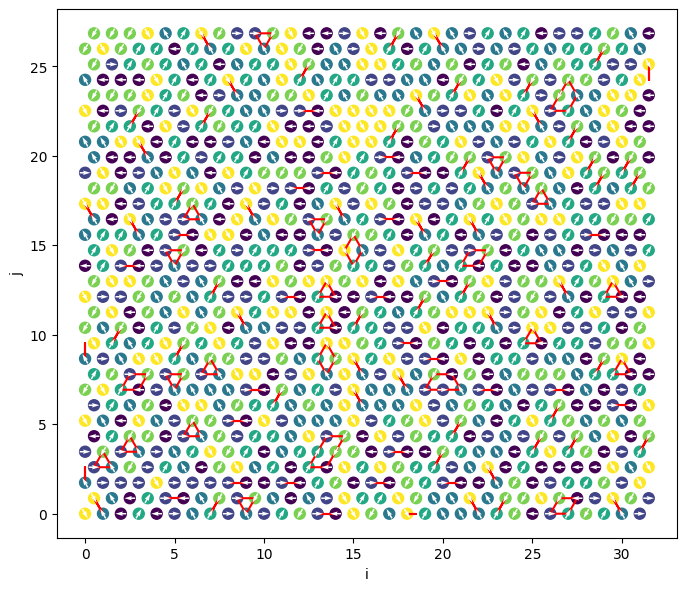

Acceptance rate 0.05514853515625


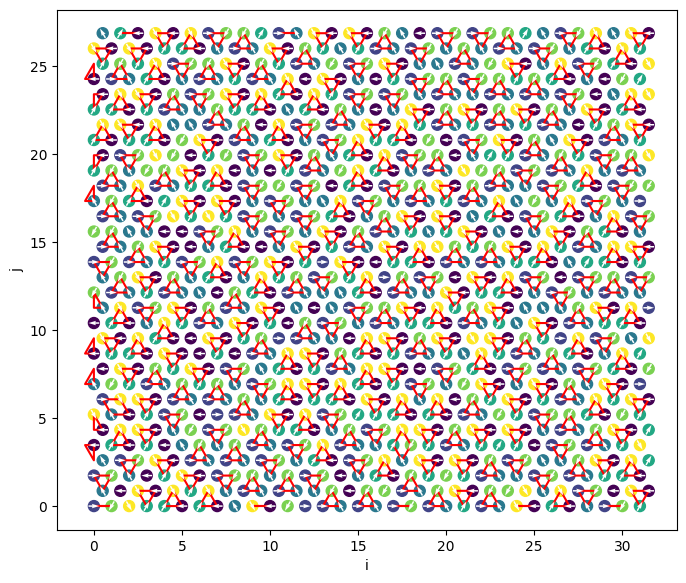

In [7]:
seed = 42069
N = 32
M = 32
dirs = left,right,up_left,up_right,down_left,down_right = 0,1,2,3,4,5
di_name = ["lx","up","ul","ur","dl","dr"]
rng = np.random.default_rng(seed)
A = rng.choice( dirs , size=(N,M) )
show_state(A)

A,th,loop_counts = run_simulation(A,rng, T=1., n_steps=10000, J1=1., J2=1.0)
print('Acceptance rate', th)
show_state(A)

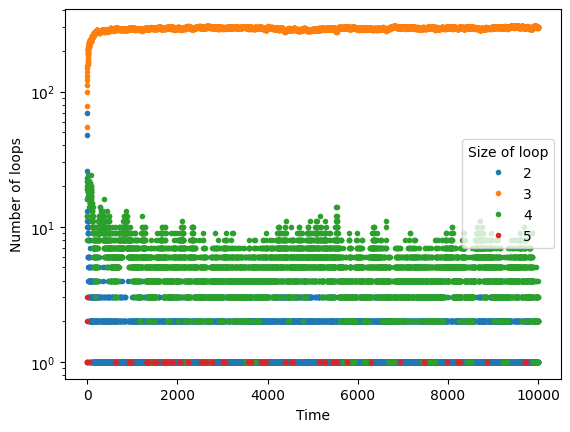

In [8]:
loop_counts
loop_count = defaultdict(list)

for step in range( len ( loop_counts ) ):
    loops_count = loop_counts[step]
    for k,n in loops_count:
        loop_count[ k ].append( [step, n] )
        
sorted_keys_loop_count = sorted( loop_count )

for k in sorted_keys_loop_count:
    step, n = np.array( loop_count[k] ).T
    plt.plot( step, n , '.', label = str(k) )
    
plt.semilogy()
plt.legend(title='Size of loop')
plt.xlabel("Time")
plt.ylabel("Number of loops")
plt.show()